# 11-4. CRPS ±10% 내 커버리지 최대 vs 순위 합산 1등 -- 구간 폭 비교

- **A**: `11-3`의 A(CRPS ±10% 안에서 커버리지 최대)
- **B**: `11-2`의 순위 합산 1등(CRPS·MSE·커버리지)

`11-3`과 같은 형태로 비교한다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
data = raw[["quarter", "X3_l1"]].dropna().reset_index(drop=True)
quarters, vals = data["quarter"].values, data["X3_l1"].values.astype(float)
var_std = vals.std()
ALPHA_IS = 0.10



def rows_of(key):
    m, sc, g = key
    d = res[(res["모델"] == m) & (res["스케일"] == sc) & (res["구간"] == g)].sort_values(["origin", "h"]).reset_index(drop=True)      # 11-1 결과 (확정된 오차만 쓴 리샘플링)
    return d.assign(구간폭=(d["hi"] - d["lo"]) / var_std)


res = pd.read_pickle("../cache/cache_107_rank_compare_df.pkl")           # 11-1의 CRPS 계산 결과
tab = res.groupby(["모델", "스케일", "구간", "origin"])[["crps_ensemble"]].mean().groupby(["모델", "스케일", "구간"]).mean()
tab["커버리지(%)"] = [rows_of(k)["적중"].mean() for k in tab.index]
tab["MSE"] = [rows_of(k)["MSE"].mean() for k in tab.index]
tab["구간폭"] = [rows_of(k)["구간폭"].mean() for k in tab.index]
tab = tab.sort_values("crps_ensemble")
print(len(tab), "개 조합")

16 개 조합


## 1. 모델 선정

A는 `11-3`의 A, B는 `11-2`의 순위 합산 1등이다.

In [2]:
rk = pd.DataFrame({"순위 crps_ensemble": tab["crps_ensemble"].rank().astype(int),
                   "순위 MSE": tab["MSE"].rank(method="min").astype(int),
                   "순위 커버리지": (tab["커버리지(%)"] - 90).abs().rank().astype(int)})
rk["순위 합산"] = rk.sum(axis=1)
rk = rk.sort_values(["순위 합산", "순위 crps_ensemble"])
best = tab["crps_ensemble"].min()
within = tab[(tab["crps_ensemble"] - best).abs() <= 0.10 * best]          # 1등 기준 ±10%
A = within["커버리지(%)"].idxmax()
B = rk.index[0]
print(f"CRPS 1등 {best:.4f}, ±10% 범위 {0.90 * best:.4f}~{1.10 * best:.4f} -> 안에 드는 조합 {len(within)}개")
print("모델 A (CRPS ±10% 안에서 커버리지 최대):", A)
print("모델 B (순위 합산 1등):", B)
sel = pd.concat([tab.loc[[A, B]].set_index(pd.Index(["A", "B"])), rk.loc[[A, B]].set_index(pd.Index(["A", "B"]))], axis=1)
display(sel.round(4))

CRPS 1등 0.5783, ±10% 범위 0.5204~0.6361 -> 안에 드는 조합 9개
모델 A (CRPS ±10% 안에서 커버리지 최대): ('GARCH', '원', '리샘플링')
모델 B (순위 합산 1등): ('SV', '원', '리샘플링')


,crps_ensemble,커버리지(%),MSE,구간폭,순위 crps_ensemble,순위 MSE,순위 커버리지,순위 합산
A,0.6248,84.0909,1.0674,5.0117,9,7,3,19
B,0.5987,82.9545,1.0526,3.4805,7,1,4,12


## 2. 예측 시점별 구간 그림

파랑 = A, 주황 = B, 빨강 = 실제값(둘 다 안이면 O, 하나라도 밖이면 X).

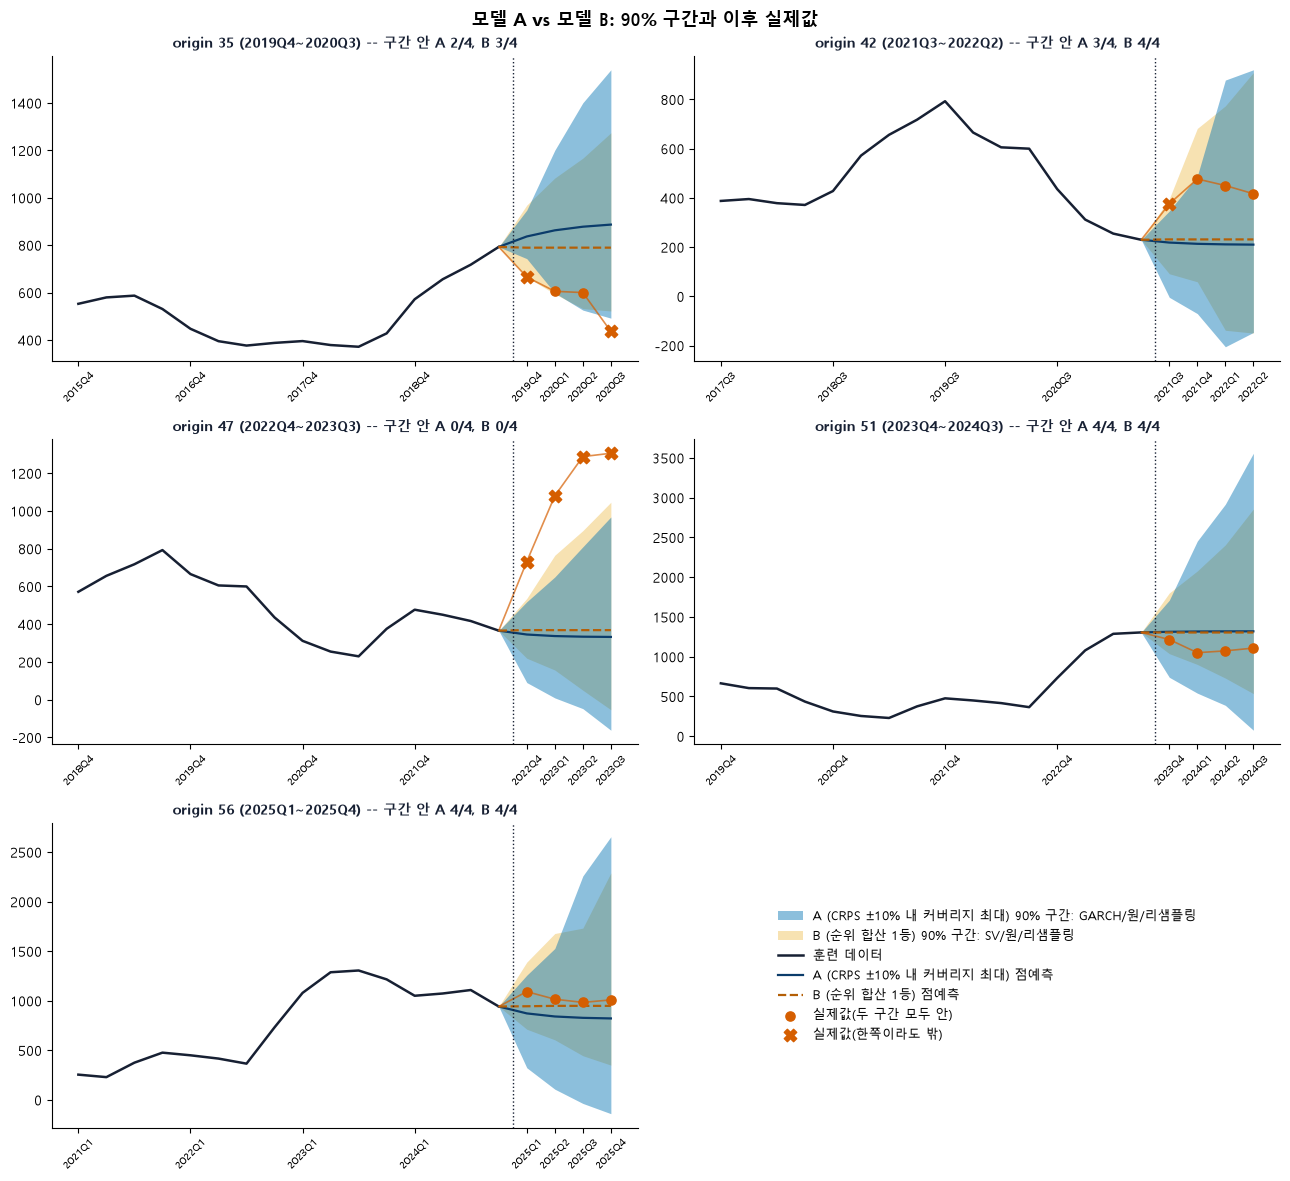

In [3]:
ra, rb = rows_of(A), rows_of(B)
ORIGINS = [35, 42, 47, 51, 56]
HIST = 16
na, nb_ = "/".join(A), "/".join(B)
LA, LB = "A (CRPS ±10% 내 커버리지 최대)", "B (순위 합산 1등)"


def draw(ax, o):
    a, b = ra[ra["origin"] == o], rb[rb["origin"] == o]
    x_hist, x_fc = np.arange(o - HIST, o), np.arange(o, o + 4)
    xs = np.r_[o - 1, x_fc]
    ax.fill_between(xs, np.r_[vals[o - 1], a["lo"].values], np.r_[vals[o - 1], a["hi"].values], color="#0072B2", alpha=0.45, linewidth=0, zorder=2, label=f"{LA} 90% 구간: {na}")
    ax.fill_between(xs, np.r_[vals[o - 1], b["lo"].values], np.r_[vals[o - 1], b["hi"].values], color="#E69F00", alpha=0.30, linewidth=0, zorder=1, label=f"{LB} 90% 구간: {nb_}")
    ax.plot(x_hist, vals[o - HIST:o], color="#172033", linewidth=1.8, label="훈련 데이터")
    ax.plot(xs, np.r_[vals[o - 1], a["fc"].values], color="#0B3C6B", linewidth=1.6, label=f"{LA} 점예측")
    ax.plot(xs, np.r_[vals[o - 1], b["fc"].values], color="#B45F06", linewidth=1.6, linestyle="--", label=f"{LB} 점예측")
    act = a["actual"].values
    inside = (act >= a["lo"].values) & (act <= a["hi"].values) & (act >= b["lo"].values) & (act <= b["hi"].values)
    ax.plot(xs, np.r_[vals[o - 1], act], color="#D55E00", linewidth=1.2, alpha=0.7)
    ax.scatter(x_fc[inside], act[inside], color="#D55E00", s=44, zorder=5, label="실제값(두 구간 모두 안)")
    ax.scatter(x_fc[~inside], act[~inside], color="#D55E00", marker="X", s=80, zorder=5, label="실제값(한쪽이라도 밖)")
    ax.axvline(o - 0.5, color="#172033", linestyle=":", linewidth=1)
    ax.set_xticks(np.r_[x_hist[::4], x_fc])
    ax.set_xticklabels([quarters[i] for i in np.r_[x_hist[::4], x_fc]], fontsize=7, rotation=45)
    ia = ((act >= a["lo"].values) & (act <= a["hi"].values)).sum()
    ib = ((act >= b["lo"].values) & (act <= b["hi"].values)).sum()
    ax.set_title(f"origin {o} ({quarters[o]}~{quarters[o + 3]}) -- 구간 안 A {ia}/4, B {ib}/4", fontsize=10, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for ax, o in zip(axes.ravel(), ORIGINS):
    draw(ax, o)
h_, l_ = axes[0, 0].get_legend_handles_labels()
axes[2, 1].axis("off")
axes[2, 1].legend(h_, l_, loc="center", frameon=False, fontsize=9)
fig.suptitle("모델 A vs 모델 B: 90% 구간과 이후 실제값", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## 3. 구간 폭 비교

폭 = 90% 구간 폭 / `var_std`.

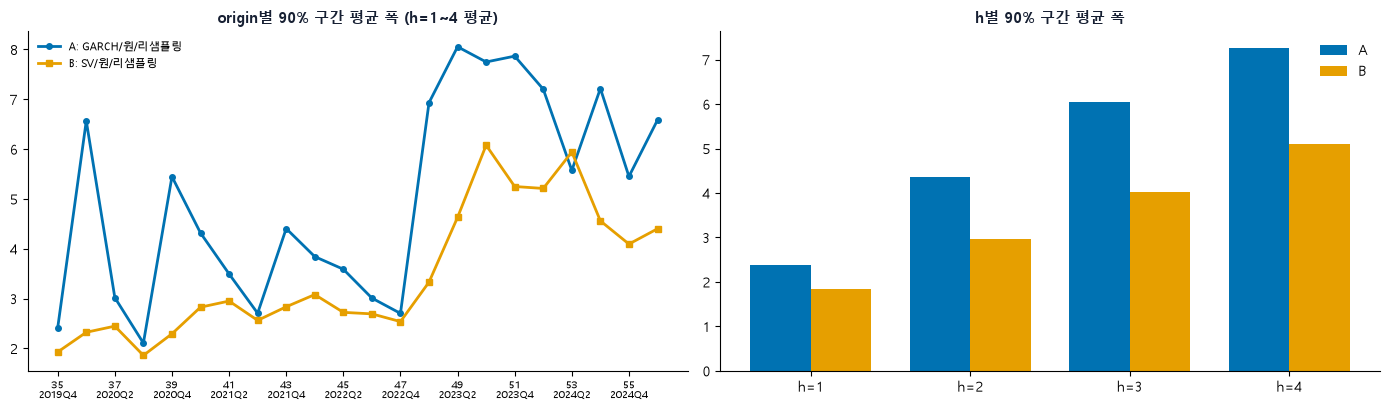

,A,B,B / A
h,,,
1,2.379,1.834,0.771
2,4.354,2.958,0.679
3,6.041,4.032,0.667
4,7.273,5.097,0.701


전체 평균 폭: A 5.012, B 3.480, 배율 0.69배


In [4]:
wa = ra.groupby("origin")["구간폭"].mean()
wb = rb.groupby("origin")["구간폭"].mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(wa))
axes[0].plot(x, wa.values, marker="o", ms=4, color="#0072B2", linewidth=2, label=f"A: {na}")
axes[0].plot(x, wb.values, marker="s", ms=4, color="#E69F00", linewidth=2, label=f"B: {nb_}")
axes[0].set_xticks(x[::2])
axes[0].set_xticklabels([f"{o}{chr(10)}{quarters[o]}" for o in wa.index[::2]], fontsize=7)
axes[0].set_title("origin별 90% 구간 평균 폭 (h=1~4 평균)", fontsize=11, fontweight="bold", color="#172033")
axes[0].legend(frameon=False, fontsize=8)
hw = pd.DataFrame({"A": ra.groupby("h")["구간폭"].mean(), "B": rb.groupby("h")["구간폭"].mean()})
bw = 0.38
axes[1].bar(np.arange(4) - bw / 2, hw["A"], bw, color="#0072B2", label="A")
axes[1].bar(np.arange(4) + bw / 2, hw["B"], bw, color="#E69F00", label="B")
axes[1].set_xticks(range(4))
axes[1].set_xticklabels([f"h={h}" for h in hw.index])
axes[1].set_title("h별 90% 구간 평균 폭", fontsize=11, fontweight="bold", color="#172033")
axes[1].legend(frameon=False)
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()
hw["B / A"] = hw["B"] / hw["A"]
display(hw.round(3))
print("전체 평균 폭: A %.3f, B %.3f, 배율 %.2f배" % (ra["구간폭"].mean(), rb["구간폭"].mean(), rb["구간폭"].mean() / ra["구간폭"].mean()))

### 3-1. 구간 폭과 실제 데이터

폭을 수준 y, Δy와 맞춰 보고 상관을 구한다(origin 22개).

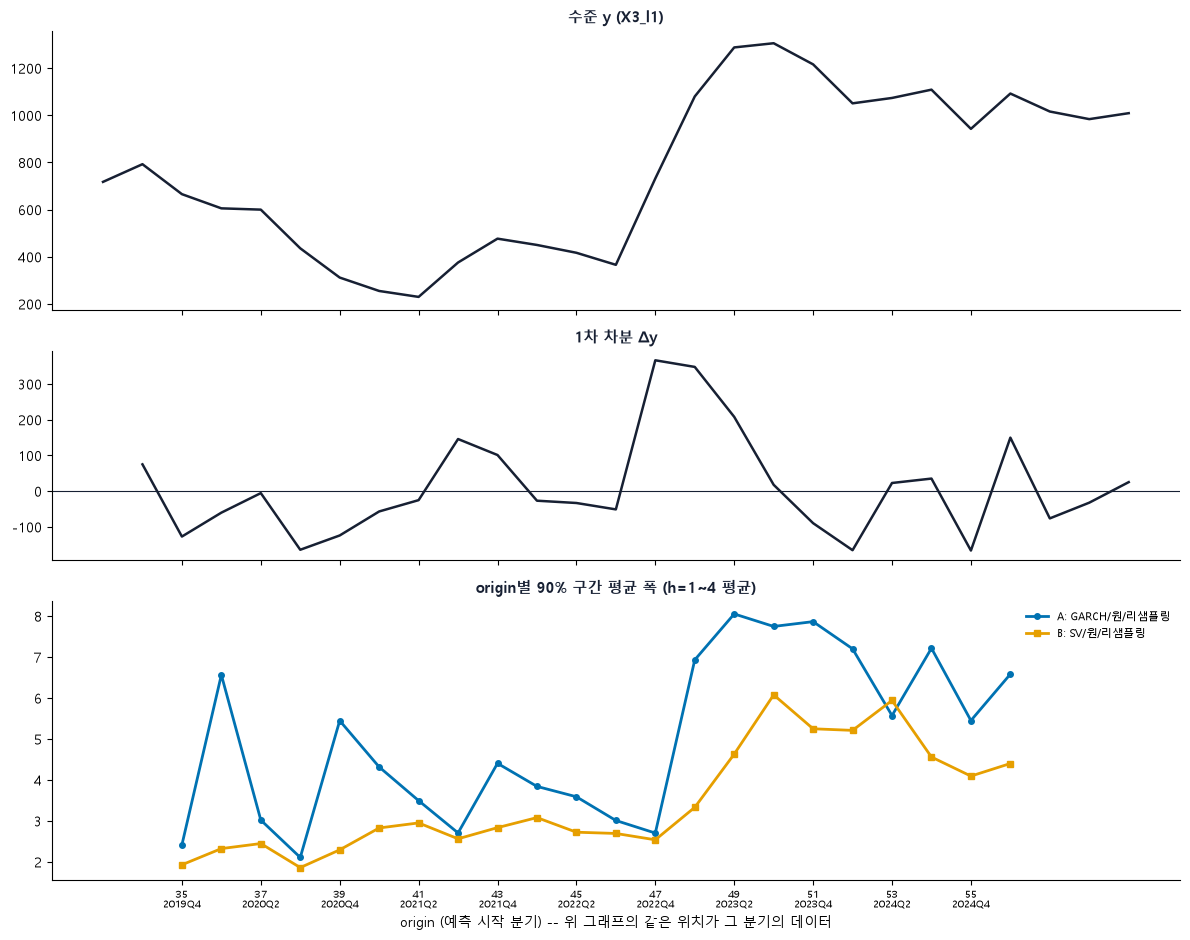

,A,B
origin 직전 수준 y,0.766,0.825
직전 8분기 Δy 표준편차,0.783,0.894


In [5]:
sc = list(wa.index)
t0 = sc[0] - 2
tt = np.arange(t0, len(vals))
dyv = np.diff(vals)
fig, axes = plt.subplots(3, 1, figsize=(12, 9.5), sharex=True, gridspec_kw={"height_ratios": [1.6, 1.2, 1.6]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=11, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=11, fontweight="bold", color="#172033")
axes[2].plot(sc, wa.values, marker="o", ms=4, color="#0072B2", linewidth=2, label=f"A: {na}")
axes[2].plot(sc, wb.values, marker="s", ms=4, color="#E69F00", linewidth=2, label=f"B: {nb_}")
axes[2].set_title("origin별 90% 구간 평균 폭 (h=1~4 평균)", fontsize=11, fontweight="bold", color="#172033")
axes[2].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[2].set_xticks(sc[::2])
axes[2].set_xticklabels([f"{o}{chr(10)}{quarters[o]}" for o in sc[::2]], fontsize=7)
axes[2].set_xlabel("origin (예측 시작 분기) -- 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()

lvl = np.array([vals[o - 1] for o in sc])                               # origin 직전 수준
vol = np.array([np.std(np.diff(vals[o - 9:o])) for o in sc])            # 직전 8분기 Δy 표준편차
cor = pd.DataFrame({"A": [np.corrcoef(wa.values, lvl)[0, 1], np.corrcoef(wa.values, vol)[0, 1]],
                    "B": [np.corrcoef(wb.values, lvl)[0, 1], np.corrcoef(wb.values, vol)[0, 1]]},
                   index=["origin 직전 수준 y", "직전 8분기 Δy 표준편차"])
display(cor.round(3))

## 4. 같은 폭 · 같은 커버리지로 비교

구간을 점예측 중심으로 k배 조정해 폭이나 커버리지를 맞춘다. 구간 점수 = 폭 + 20 x 벗어난 거리, `var_std`로 나눔(낮을수록 좋음).

In [6]:
def stat(g, k, logmode):
    fc, lo, hi, a = g["fc"].values, g["lo"].values, g["hi"].values, g["actual"].values
    if logmode:
        l = np.exp(np.log(fc) + k * (np.log(lo) - np.log(fc)))
        u = np.exp(np.log(fc) + k * (np.log(hi) - np.log(fc)))
    else:
        l, u = fc + k * (lo - fc), fc + k * (hi - fc)
    cov = np.mean((a >= l) & (a <= u)) * 100
    w = np.mean(u - l) / var_std
    isc = np.mean((u - l) + (2 / ALPHA_IS) * np.maximum(l - a, 0) + (2 / ALPHA_IS) * np.maximum(a - u, 0)) / var_std
    return cov, w, isc


KS = np.linspace(0.05, 10, 1980)
lgA, lgB = A[1] == "로그", B[1] == "로그"


def k_for_cov(g, lg, target=90):
    return next((k for k in KS if stat(g, k, lg)[0] >= target), np.nan)


def k_for_width(g, lg, target):
    return min(KS, key=lambda k: abs(stat(g, k, lg)[1] - target))


wA, wB = stat(ra, 1, lgA)[1], stat(rb, 1, lgB)[1]
rows = [("A 원래", 1.0, *stat(ra, 1, lgA)), ("B 원래", 1.0, *stat(rb, 1, lgB))]
kb = k_for_width(rb, lgB, wA)
rows.append(("B를 A의 폭으로 줄임", kb, *stat(rb, kb, lgB)))
ka = k_for_width(ra, lgA, wB)
rows.append(("A를 B의 폭으로 늘림", ka, *stat(ra, ka, lgA)))
for nm, g, lg in [("A", ra, lgA), ("B", rb, lgB)]:
    k = k_for_cov(g, lg)
    rows.append((f"{nm}를 커버리지 90%로 맞춤", k, *stat(g, k, lg)))
eq = pd.DataFrame(rows, columns=["비교", "배율 k", "커버리지(%)", "폭", "구간 점수"]).set_index("비교")
display(eq.round(3))

,배율 k,커버리지(%),폭,구간 점수
비교,,,,
A 원래,1.000,84.091,5.012,6.818
B 원래,1.000,82.955,3.480,5.153
B를 A의 폭으로 줄임,1.438,95.455,5.004,5.368
A를 B의 폭으로 늘림,0.694,77.273,3.476,6.699
A를 커버리지 90%로 맞춤,1.282,90.909,6.424,7.345
B를 커버리지 90%로 맞춤,1.297,90.909,4.514,5.113


## 5. 결론

**순위 합산 1등(B)은 A보다 커버리지만 조금 낮고(-1.1%p) 구간이 31% 좁으며, 같은 커버리지로 맞추면 B가 더 좁다.**

| | 모델 | CRPS | MSE | 커버리지 | 폭 | 순위 합산 |
|---|---|---|---|---|---|---|
| A | GARCH / 원 / 리샘플링 | 0.6248 (9위) | 1.067 | 84.1% | 5.01 | 19 |
| B | SV / 원 / 리샘플링 | 0.5987 (7위) | 1.053 | 83.0% | 3.48 (A의 0.69배) | 12 |

- **같은 커버리지(90.9%)에서**: B의 폭 4.51, A의 폭 6.42로 B가 30% 좁다(구간 점수 5.11 vs 7.35). 같은 폭에서는 B를 A의 폭으로 늘리면 95.5%(A 84.1%), A를 B의 폭으로 줄이면 77.3%(B 83.0%)다.
- **`11-3`과 비교**: 같은 A에 대해 `11-3`의 B는 4.0배 넓었고 이 B는 30% 좁다. 효율이 정반대다.
- **의미**: 이 쌍에서는 순위 합산이 폭 효율이 좋은 모델을 골랐다. 선정 방식과 구간 모델(GARCH vs SV)이 모두 달라 차이가 MSE 효과인지는 구분되지 않는다(MSE 차이 1.4%).
- 한계: 모델 한 쌍의 사례이고 22개 origin이 겹치며 유의성 검정은 하지 않았다.